<p align="center">
  <img src="https://www.copernicuslac-chile.eu/wp-content/uploads/2024/05/logo_copernicuslac_chile.svg" alt="Copernicus LAC Chile" width="1200"/>
</p>

# Taller Océanos: México, ODS 14
## SST y clorofila de CopernicusLAC frente a los indicadores del ODS 14 y los datos del SIODS (INEGI)

Este notebook es la guía práctica del bloque **Monitoreo de Costas** (11 de noviembre de 2026, 13:00–15:30). Trabaja con los productos mensuales de **temperatura superficial del mar (SST)** y **clorofila-a (CHL)** de CopernicusLAC para 2024 y con los valores oficiales que publica México en el **SIODS** y la ONU.

Cada grupo elige una de las cinco áreas del mar mexicano: Baja California – Pacífico, Golfo de California, Pacífico sur, Golfo de México o Caribe mexicano. Los datos de 2024 son los únicos configurados en este notebook.

## Índice del taller

0. [Contexto y configuración](#parte-0)
1. [Exploración de los productos](#parte-1)
2. [Selección del área de trabajo](#parte-2)
3. [ODS 14.1.1: clorofila y eutrofización](#parte-3)
4. [ODS 14.5.1: cobertura de zonas protegidas](#parte-4)
   - [Preguntas de discusión final](#discusion)
   - [Anexo opcional](#anexo)

El flujo es el siguiente:

```text
reconocer los datos → elegir área → leer SST y CHL → comparar resoluciones  → conocer el indicador 14.1.1 → reproducir el 14.5.1 del SIODS → ficha
```

| Indicador | ¿Lo publica México en el SIODS (INEGI)? | Valor oficial de referencia | Papel de los productos CopernicusLAC |
|---|---|---|---|
| **14.1.1** Eutrofización costera | No | Porcentaje de superficie marina con aumentos inusuales de clorofila-a: 2,35 % (2022) | **Componente** Concentración de clorofila-a y análisis de variaciones espaciales y temporales |
| **14.5.1** Zonas protegidas | **Sí**: 23,78 % (2024) | ONU, método KBA: 64,33 % (2024) | **Contexto** ambiental de las ANP; el cálculo es vectorial |

---

<a id="parte-0"></a>

## Parte 0. Contexto y configuración

### Objetivo

Preparar el entorno y cargar todos los insumos: los dos NetCDF de 2024, las capas vectoriales (ANP federales de CONANP, ZEE, áreas de trabajo) y la tabla de valores oficiales del SIODS y de la ONU.

### Cómo recorrer este notebook

Ejecuta las celdas de arriba hacia abajo. En los puntos marcados como **Revisión**, detente para leer la tabla o el mapa antes de avanzar. Las selecciones se hacen con **menús interactivos**; si no los ves, revisa que el kernel sea **Python (2026coplac)**.

Esta celda carga las funciones del taller (`scripts/oceanos_mexico_functions.py`) y los datos. **Tarda uno o dos minutos.**

In [1]:
import os, sys, warnings
from pathlib import Path

# Configuración geoespacial para Windows (Conda)
if os.name == "nt" and os.environ.get("CONDA_PREFIX"):
    raiz = Path(os.environ["CONDA_PREFIX"]) / "Library" / "share"
    proj = raiz / "proj"
    if (proj / "proj.db").is_file():
        os.environ["PROJ_DATA"] = str(proj)
        os.environ["PROJ_LIB"] = str(proj)
        from pyproj import datadir
        datadir.set_data_dir(str(proj))

warnings.filterwarnings("ignore")

# Localizar el proyecto e importar las funciones
BASE_DIR = next(
    p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    if (p / "scripts").is_dir() and (p / "environment.yml").exists())
sys.path.insert(0, str(BASE_DIR / "scripts"))

from oceanos_mexico_functions import *

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 12,
    "axes.labelsize": 10})

preparar_entorno();

AVISO: CMC_SST_2024MM_2026-10-13T153231_L4.nc: lat sin units; interpretación geográfica confirmada explícitamente.
AVISO: CMC_SST_2024MM_2026-10-13T153231_L4.nc: lon sin units; interpretación geográfica confirmada explícitamente.
AVISO: CMC_CHL_2024MM_2026-10-13T153338_L4.nc: lat sin units; interpretación geográfica confirmada explícitamente.
AVISO: CMC_CHL_2024MM_2026-10-13T153338_L4.nc: lon sin units; interpretación geográfica confirmada explícitamente.
✅ Datos cargados
   SST: 12 meses, grilla 936×1714
   CHL: 12 meses, grilla 1871×3427
   ANP federales: 232 (con superficie marina: 40)


### 0.2 ¿Hay internet en la sala?

El notebook funciona **sin internet**: los datos, los menús, el visor mensual y la calculadora son locales. Solo dos elementos dependen de la red:

- el **mapa interactivo** de la Parte 2 (Folium y el fondo de OpenStreetMap se cargan desde internet);
- el logo del encabezado.

La celda siguiente comprueba la conexión. Si no hay internet, el mapa interactivo se sustituye por un **mapa estático** con las ANP numeradas y una tabla con sus nombres.

Si la red de la sala es lenta o inestable, fuerza el modo sin internet escribiendo `SIN_INTERNET = True` antes de ejecutar.

In [2]:
# None = detectar automáticamente · True = trabajar sin internet · False = forzar el mapa interactivo
SIN_INTERNET = None

configurar_conexion(SIN_INTERNET)

🌐 Modo CON internet (detectado automáticamente): se usará el mapa interactivo con fondo de OpenStreetMap.


False

<a id="parte-1"></a>

## Parte 1. Exploración de los productos

### Objetivo del bloque

Reconocer qué datos tenemos antes de usarlos: periodo, grilla y huella de los NetCDF, y dónde quedan las cinco áreas de trabajo.

- **SST** (`analysed_sst`): producto L4 mensual, grilla de 0,02°, convertido de K a °C.
- **CHL** (`chlor_a`): producto L4 mensual multisensor, grilla de 0,01° (~1 km), en mg m⁻³.

Los productos **L4** combinan observaciones satelitales con métodos de análisis espacial y temporal para generar campos regulares. Algunos valores pueden ser estimados y no corresponder a observaciones directas (como inferencias por interpolación o modelos). Por ello, una alta cobertura espacial no garantiza la misma confianza en todos los píxeles.

### Paso 1.1 Inventario y áreas

**Resultado esperado:** una tabla con los dos archivos (12 meses de 2024) y un mapa con las cinco áreas recortadas a la ZEE.

,tipo,archivo,fechas,inicio,fin,lat_min,lat_max,lon_min,lon_max,dlat_grados
0,SST,CMC_SST_2024MM_2026-10-13T153231_L4.nc,12,2024-01-01 00:00:00,2024-12-01 00:00:00,13.820,32.520,-120.139999,-85.879997,0.02
1,CHL,CMC_CHL_2024MM_2026-10-13T153338_L4.nc,12,2024-01-01 00:00:00,2024-12-01 00:00:00,13.825,32.525,-120.145000,-85.885000,0.01


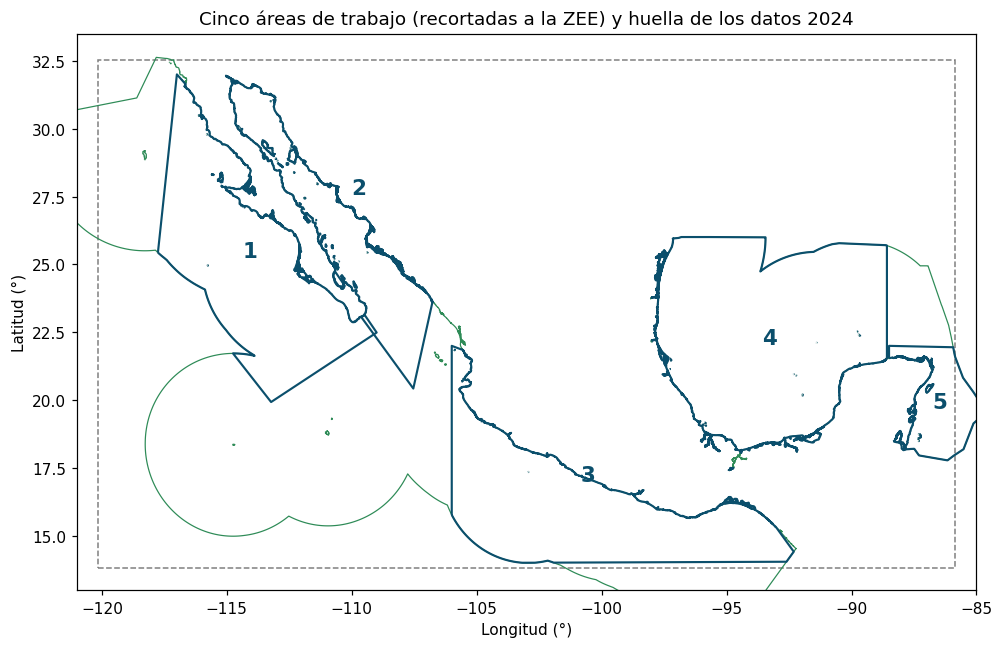

,id_area,nombre,poem_referencia
0,1,Baja California – Pacífico,POEM Pacífico Norte (2018)
1,2,Golfo de California,POEM Golfo de California (2006)
2,3,Pacífico sur,"POEM Pacífico Centro-Sur (en preparación, 2023)"
3,4,Golfo de México,POEM Golfo de México y Mar Caribe (2012)
4,5,Caribe mexicano,POEM Golfo de México y Mar Caribe (2012)


In [3]:
explorar_productos()

**Revisión:** ¿la huella de los datos (rectángulo gris) cubre toda la ZEE mexicana? ¿Qué parte del Caribe queda fuera? ¿Qué consecuencias tendría para el análisis seleccionar una región que no esté completamente cubierta por los productos?


<a id="parte-2"></a>

## Parte 2. Selección del área de trabajo

### Objetivo del bloque

Elegir el área del grupo. Cada área se asocia, de forma aproximada, a un Programa de Ordenamiento Ecológico Marino (POEM), que se usará en la Parte 5.

### Paso 2.1 Elegir área y grupo

1. elige el área en el menú;
2. escribe el nombre del grupo (letras, números y guion bajo);
3. pulsa **Confirmar área**.

**Resultado esperado:** un mapa del área seleccionada y sus áreas naturales protegidas. Si no hay conexión a internet, se mostrará una versión estática.

In [4]:
launch_seleccion_area(id_area_inicial=4, grupo_inicial='grupo_01')

<a id="parte-3"></a>

## Parte 3. ODS 14.1.1: clorofila y eutrofización

### Objetivo del bloque

Explorar cómo los datos satelitales pueden contribuir al monitoreo de las condiciones ambientales de las costas mexicanas.

El indicador ODS 14.1.1 considera la eutrofización costera y la contaminación por plásticos. En este ejercicio nos concentraremos únicamente en la clorofila-a, una variable relacionada con la biomasa del fitoplancton.

**¿Qué hace UNEP?**
Utiliza información satelital y datos históricos para identificar aumentos inusuales de clorofila-a y evaluar su distribución en las aguas marinas de cada país.

**¿Qué haremos nosotros?**
- Explorar la distribución mensual de clorofila-a y temperatura superficial del mar durante 2024.
- Comparar la información de clorofila-a a diferentes resoluciones espaciales.
- Identificar las posibilidades y limitaciones de estos datos para el monitoreo costero.

Importante: una concentración elevada de clorofila-a no demuestra por sí sola eutrofización. Los resultados de este ejercicio son exploratorios y no reproducen el indicador oficial de Naciones Unidas.

### Paso 3.1 Visor mensual de SST y CHL

Cambia la variable y mueve el mes. El visor arranca en el mes sugerido para tu área.

**Revisión:** ¿dónde hay agua fría junto a la costa? ¿Coincide con CHL alta?

In [5]:
launch_visor_mensual()

### Interpretación de los patrones observados

La temperatura superficial del mar y la clorofila-a permiten explorar diferentes procesos oceanográficos:

- **Surgencia costera:** el ascenso de aguas frías y ricas en nutrientes puede favorecer concentraciones elevadas de clorofila-a.
- **Desembocaduras y zonas costeras:** los aportes continentales pueden influir en la productividad del agua y también afectar las estimaciones satelitales.
- **Variabilidad estacional:** la temperatura y la clorofila-a pueden cambiar entre meses debido a procesos naturales y actividades humanas.

**Precaución:** los datos satelitales de clorofila-a necesitan validación, especialmente en aguas costeras turbias. Una concentración elevada no permite identificar por sí sola su causa ni confirmar eutrofización.

### Paso 3.2 Ciclo anual y concentración de clorofila

**Resultado esperado**: gráficos con la variación mensual de temperatura y clorofila-a durante 2024, junto con un resumen de la concentración de clorofila-a en el área seleccionada.

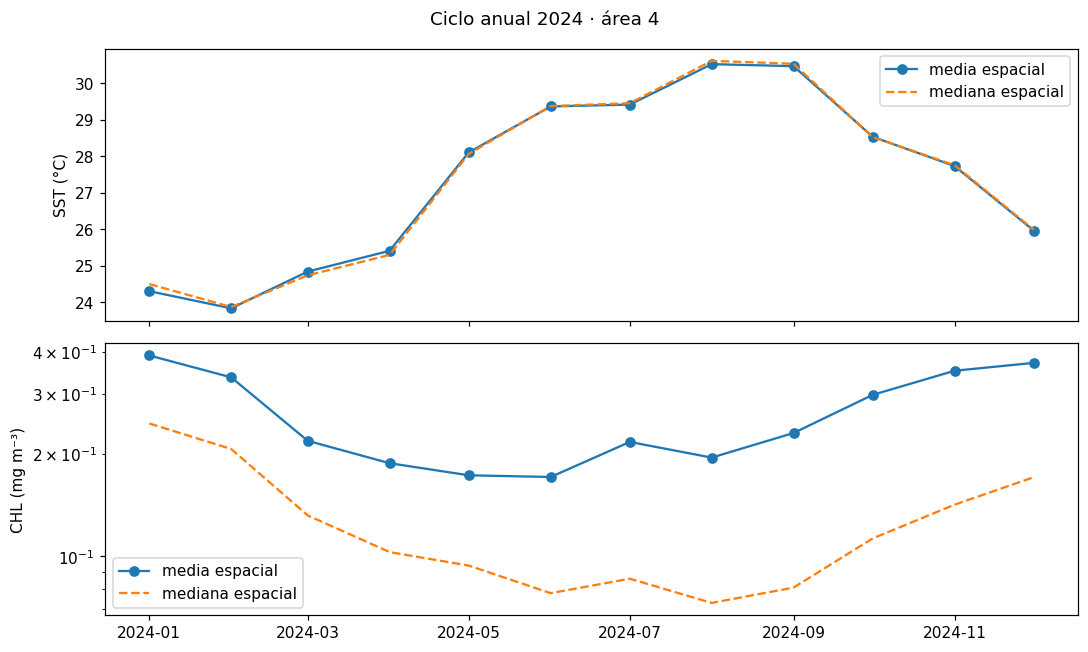

CHL media 2024 (media de 12 meses): 0.262 mg m⁻³ = 0.000262 mg L⁻¹
Cobertura espacial mínima de CHL: 95.4 %


In [6]:
run_series_14_1_1();

### Paso 3.3 ¿Qué ocurre cuando reducimos la resolución espacial?

Los productos globales de clorofila-a utilizados por Naciones Unidas tienen una resolución aproximada de 4 km. CopernicusLAC Chile ofrece información a ~1 km, lo que permite representar estructuras costeras de menor tamaño.

En este ejercicio agregaremos los datos de CopernicusLAC a una grilla de aproximadamente 4 km y compararemos ambas representaciones.

**Observaremos:**
- Cómo cambia la distribución espacial de la clorofila-a.
- Qué estructuras costeras se distinguen a diferentes resoluciones.
- Cómo cambian los valores resumidos para el área de estudio.

La comparación utiliza el mismo producto de origen, pero representado a distintas resoluciones. Por lo tanto, permite evaluar los efectos del procesamiento espacial, **no reproducir directamente el producto global de UNEP**, es decir, el algoritmo y los sensores siguen siendo los de CopernicusLAC Chile, por lo que, por ejemplo, no hay referencia 2000–2004

**Resultado esperado:** dos mapas comparables, uno a ~1 km y otro a ~4 km, junto con un resumen de las diferencias.

Media anual: 0.262 mg m⁻³ a ~1 km · 0.260 mg m⁻³ a 4 km
Celdas de ~1 km que caen en píxeles de 4 km descartados: 0.29 %
Mediana de CHL en esas celdas: 1.29 mg m⁻³ frente a 0.13 mg m⁻³ en toda el área


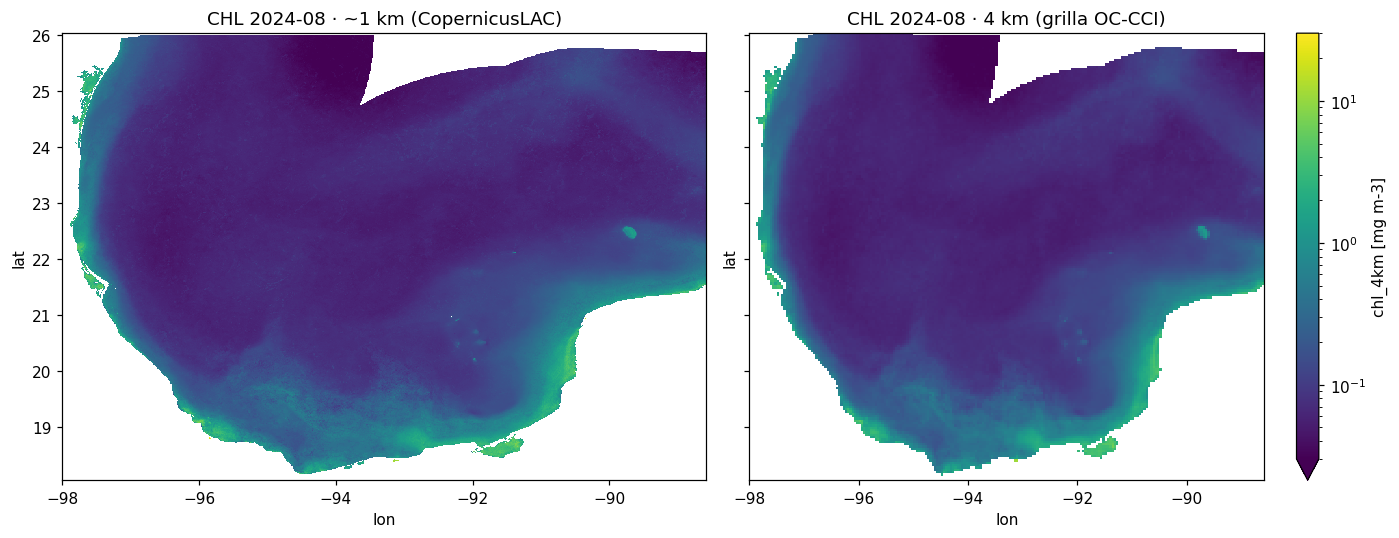

In [7]:
run_4km();

**Lectura.** Al reducir la resolución espacial, varias celdas de alta resolución se combinan para representar un área mayor. Esas celdas son sobre todo las de la costa, donde la CHL es varias veces más alta que la mediana del área. Es decir, esto puede suavizar los contrastes y dificultar la identificación de estructuras costeras pequeñas, y es en esta franja donde ocurre la eutrofización (lagunas, desembocaduras). Cuidado: en esa franja turbia la CHL satelital también es menos fiable, porque sedimento y materia orgánica disuelta la sobrestiman.

Observe también el mapa de ~1 km: Si aparecen patrones rectangulares o discontinuidades que no parecen corresponder a procesos oceanográficos, conviene revisarlos como posibles artefactos del producto.

### Paso 3.4 ¿Cómo se relacionan nuestros datos con el indicador oficial? ###
Naciones Unidas publica información sobre la proporción de aguas marinas que presentan aumentos inusuales de clorofila-a respecto de condiciones históricas.

Nuestros datos de 2024 permiten caracterizar concentraciones y patrones costeros, pero no calcular directamente ese porcentaje oficial, que requiere una metodología y una serie histórica específicas.

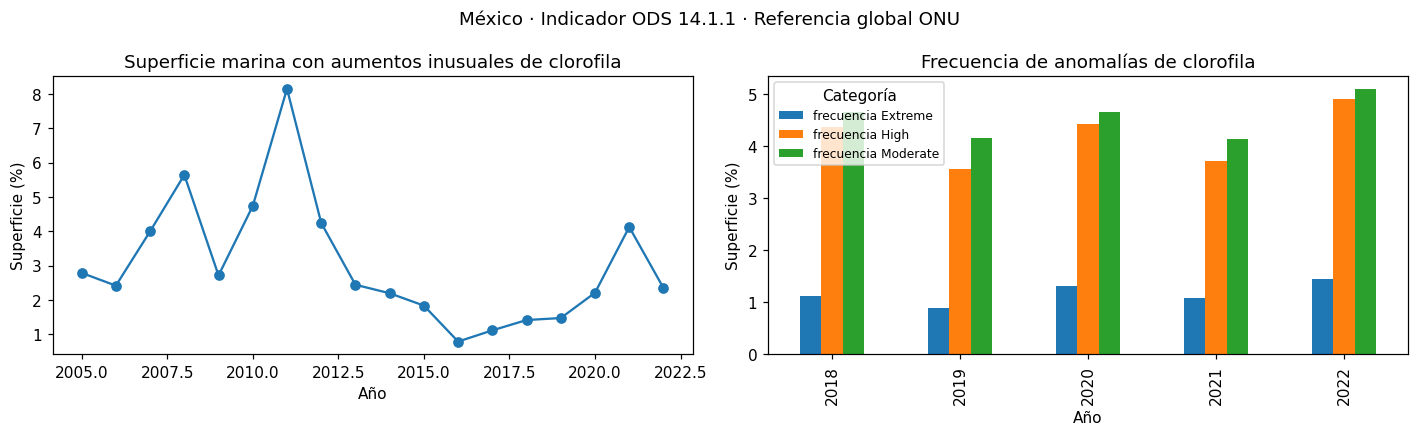

Último año disponible: 2022 · Superficie con aumentos inusuales de CHL: 2.35 %


In [8]:
show_referencia_onu_14_1_1()

### Revisión de resultados

1. ¿Qué patrones de temperatura y clorofila-a encontramos en el área seleccionada?
2. ¿Qué diferencias aparecen al comparar la información a ~1 km y ~4 km?
3. ¿Qué información adicional necesitamos para utilizar estos datos en el seguimiento nacional de la eutrofización costera?

### ¿Cómo podemos avanzar hacia una aplicación nacional?

Los resultados de este ejercicio muestran algunas posibilidades de los datos satelitales para el monitoreo costero. Sin embargo, su utilización en estadísticas nacionales requiere trabajo adicional.

| Aspecto | ¿Qué necesitamos? |
|---|---|
| **Continuidad temporal** | Series satelitales consistentes que permitan estudiar cambios entre años. |
| **Validación** | Mediciones de clorofila-a en terreno y conocimiento de las condiciones locales. |
| **Metodología compartida** | Definir junto con las instituciones mexicanas las áreas prioritarias, los criterios de calidad y los procedimientos de análisis. |


**¿Qué aporta CopernicusLAC?**
Productos regionales de clorofila-a a ~1 km, herramientas de procesamiento y experiencia en integración de observaciones satelitales.

**¿Qué buscamos?**
Identificar oportunidades de colaboración con las instituciones mexicanas para evaluar y mejorar la utilidad de esta información en el monitoreo costero.

<a id="parte-4"></a>

## Parte 4. ODS 14.5.1: protección de los ecosistemas marinos

### ¿Qué queremos evaluar?

Este indicador permite analizar la cobertura de las áreas marinas protegidas.

México dispone de información oficial sobre la superficie marina de las Áreas Naturales Protegidas (ANP), publicada por instituciones nacionales.

En este ejercicio utilizaremos esa información para:

1. Explorar la evolución de la superficie marina protegida.
2. Reproducir el porcentaje de cobertura a partir de superficies oficiales.
3. Comparar los resultados nacionales con otras formas de análisis territorial.

**Importante:** la metodología nacional y la referencia internacional pueden utilizar delimitaciones y criterios diferentes. Sus resultados no deben interpretarse como equivalentes.

### Paso 4.1. ¿Cómo ha evolucionado la protección marina en México?

Para calcular la proporción de superficie marina protegida necesitamos dos elementos:

- **Superficie protegida:** área marina declarada bajo alguna categoría de protección.
- **Superficie de referencia:** extensión marina respecto de la cual calculamos el porcentaje.

En este ejercicio reconstruiremos la evolución histórica de la superficie protegida utilizando los registros de las Áreas Naturales Protegidas (ANP) de CONANP y la compararemos con la información publicada en el SIODS.

**Resultado esperado:** un gráfico de evolución temporal y una tabla que permita comparar la superficie protegida registrada con el valor oficial.

**Para interpretar:** la reconstrucción asigna la superficie marina actual de cada ANP al año de su primer decreto. Es una simplificación que no necesariamente considera modificaciones posteriores de sus límites o superficies.

**Pregunta:** ¿En qué períodos aumenta más la superficie protegida? ¿Qué información necesitaríamos para explicar esos cambios?

,año,SIODS_ha,S_MARINA_ha,diferencia_ha,SIODS_pct
23,2016,54665351.0,5.466535e+07,0.312856,17.354521
24,2017,69458613.0,6.945861e+07,0.212856,22.050913
25,2018,69458613.0,6.945861e+07,0.212856,22.050913
26,2019,69458613.0,6.945861e+07,0.212856,22.050913
27,2020,69458613.0,6.945861e+07,0.212856,22.050913
28,2021,69458613.0,6.945861e+07,0.212856,22.050913
29,2022,69458613.0,6.945861e+07,0.212856,22.050913
30,2023,69458613.0,6.945861e+07,0.212856,22.050910
31,2024,74904155.0,7.490416e+07,0.388631,23.779701
32,2025,74904155.0,7.490416e+07,0.388631,23.779701


Diferencia máxima del numerador: 0.4 ha
Superficie marina de referencia estimada a partir del SIODS: 3,149,920 km²


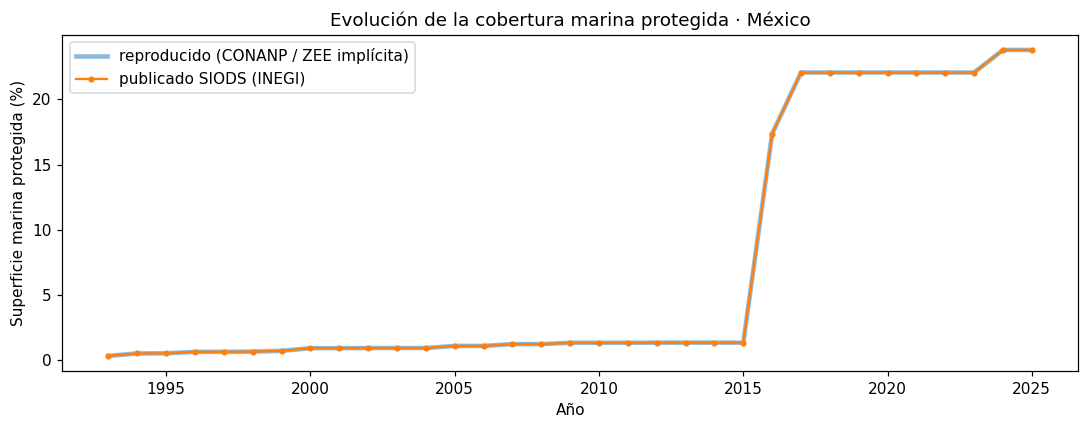

In [9]:
run_reproduccion_siods();

### Paso 4.2. Calculadora de cobertura marina protegida

El porcentaje de superficie protegida se calcula como:

$$ \text{Cobertura marina (\%)} = \frac{\text{Superficie marina protegida}}{\text{Superficie marina de referencia}} \times 100 $$

En la calculadora podemos combinar dos formas de medir la superficie protegida:

- **Superficie declarada:** información registrada por CONANP.
- **Superficie geométrica:** calculada a partir de los polígonos de ANP que intersectan la ZEE.

También podemos utilizar diferentes superficies de referencia.

**Actividad:**

1. Calcula la cobertura utilizando los valores nacionales de referencia.
2. Cambia únicamente el denominador.
3. Cambia únicamente el numerador.
4. Compara los resultados.

**Pregunta:** ¿Por qué dos cálculos de cobertura pueden entregar porcentajes distintos sin que ninguno tenga necesariamente un error matemático?

**Conclusión esperada:** para interpretar y comparar indicadores territoriales es fundamental documentar las fuentes, las delimitaciones y el método de cálculo.

In [10]:
launch_calculadora_14_5_1()

### Paso 4.3. Explorar las condiciones ambientales de las áreas protegidas

Utilizaremos las capas de Áreas Naturales Protegidas (ANP) y los productos satelitales de CopernicusLAC para analizar la cobertura marina protegida y comparar las condiciones ambientales dentro y fuera de las ANP.

#### 1. Cobertura marina por categoría de manejo

La primera tabla presenta las ANP agrupadas según su categoría de manejo y compara las superficies declaradas oficialmente con las calculadas a partir de sus polígonos.

| Columna | Significado |
|---|---|
| `CAT_MANEJO` | Categoría de manejo asignada a las ANP por CONANP. |
| `n_anp` | Número de ANP pertenecientes a esa categoría. |
| `S_MARINA_km2_declarada` | Suma de las superficies marinas declaradas por CONANP, expresada en km². |
| `protegido_km2_geometrico` | Superficie calculada mediante la intersección de los polígonos de ANP con la Zona Económica Exclusiva (ZEE), expresada en km². |
| `cobertura_pct_geometrica` | Porcentaje de la ZEE cubierto por las ANP de esa categoría, calculado geométricamente. |

**¿Qué significan las categorías de manejo?**

| Sigla | Categoría | Características principales |
|---|---|---|
| RB | Reserva de la Biosfera | Protege ecosistemas representativos y su biodiversidad. Puede combinar zonas de conservación estricta con zonas de aprovechamiento sustentable. |
| PN | Parque Nacional | Conserva ecosistemas de importancia ecológica, científica o paisajística. Permite actividades compatibles, como investigación, educación y turismo regulado. |
| APFF | Área de Protección de Flora y Fauna | Protege hábitats esenciales para la conservación de especies silvestres. Puede permitir aprovechamientos regulados de recursos naturales. |
| APRN | Área de Protección de Recursos Naturales | Protege recursos naturales como suelos, cuencas y aguas, promoviendo su conservación y aprovechamiento sustentable. |
| MN | Monumento Natural | Protege elementos naturales singulares de especial interés científico, histórico o paisajístico. |
| SANT | Santuario | Protege lugares específicos de gran riqueza biológica o hábitats de especies de distribución restringida. |

*Fuente: Comisión Nacional de Áreas Naturales Protegidas (CONANP) y SEMARNAT.*

**Pregunta:** ¿Qué diferencias encontramos entre la superficie marina declarada y la calculada geométricamente? ¿A qué podrían deberse?

#### 2. Comparación ambiental dentro y fuera de las ANP

La segunda tabla resume las condiciones ambientales de 2024 utilizando las series mensuales de SST y clorofila-a.

| Columna | Significado |
|---|---|
| `variable` | Variable ambiental analizada: SST (°C) o clorofila-a (mg/m³). |
| `clase` | Ubicación de las observaciones: dentro de ANP marinas o en el resto del área seleccionada. |
| `Media 2024` | Promedio de las medias espaciales mensuales de 2024. |
| `Mínimo mensual` | Menor media espacial mensual registrada durante 2024. |
| `Máximo mensual` | Mayor media espacial mensual registrada durante 2024. |

Los resultados permiten explorar las diferencias ambientales entre las zonas protegidas y no protegidas del área de estudio.

**Preguntas para discutir:**

1. ¿Qué proporción de nuestra área seleccionada se encuentra protegida?
2. ¿Cómo varían SST y clorofila-a dentro y fuera de las ANP?
3. ¿Qué características geográficas u oceanográficas podrían explicar las diferencias?

**Importante:** estas comparaciones describen condiciones ambientales, pero no demuestran por sí solas la efectividad de las medidas de conservación. Además, la superficie declarada y la calculada geométricamente pueden diferir debido a sus fuentes, delimitaciones y criterios de cálculo.

In [11]:
run_categorias_y_area();

,CAT_MANEJO,n_anp,S_MARINA_km2_declarada,protegido_km2_geometrico,cobertura_pct_geometrica
4,RB,48,534384.88,534734.49,16.78
3,PN,79,209918.41,209907.63,6.59
0,APFF,57,3282.62,7217.62,0.23
5,SANT,28,1455.65,1496.41,0.05
1,APRN,15,0.00,0.00,0.00
2,MN,5,0.00,0.00,0.00


Área 4: 63,489 km² protegidos de 648,486 km² de ZEE = 9.8 %


Media 2024  Mínimo mensual  Máximo mensual
variable clase                                                            
CHL      dentro de ANP marinas       0.435           0.283           0.707
         resto del área              0.244           0.156           0.373
SST      dentro de ANP marinas      27.574          24.203          30.663
         resto del área             27.358          23.796          30.528

Unidades: SST en °C y CHL en mg m⁻³
Una diferencia dentro/fuera describe ubicación (costa, profundidad), no efecto de la protección.


### Revisión

1. **Fuentes de información:** ¿qué diferencias existen entre utilizar superficies declaradas y superficies calculadas a partir de polígonos?
2. **Delimitación territorial:** ¿cómo cambia el porcentaje de cobertura cuando modificamos el área de referencia?
3. **Información complementaria:** ¿qué aportan los datos de SST y clorofila-a para caracterizar las áreas marinas protegidas?

**Conclusión:** reproducir un indicador requiere conocer tanto sus datos de entrada como sus decisiones metodológicas. Los productos satelitales pueden complementar su interpretación ambiental, pero no sustituyen los datos oficiales de protección.

<a id="parte-5"></a>

## Parte 5. Exportación de resultados

### Objetivo

Guardar los resultados del ejercicio en formatos que permitan continuar su análisis fuera de JupyterLab.

Al finalizar obtendremos:

- **GeoTIFF:** mapas de SST y clorofila-a compatibles con QGIS.
- **GeoPackage:** polígonos del área de estudio y sus áreas naturales protegidas.
- **CSV y Excel:** series temporales, estadísticas y resultados calculados.
- **Ficha de resultados:** resumen del trabajo realizado por el grupo.

Estos archivos pueden ser compartidos y utilizados posteriormente en otras herramientas de análisis geoespacial.

**Exportación cartográfica**
Esta función guarda la temperatura, la clorofila-a y las capas vectoriales del área seleccionada en formatos compatibles con QGIS. Los archivos pueden abrirse mediante el Administrador de fuentes de datos de QGIS o arrastrándolos directamente al mapa.
Los raster corresponden al mes seleccionado en el visor. Para exportar otro mes, cambia la selección y vuelve a ejecutar la función.

In [12]:
exportar_capas_qgis()

✅ Capas exportadas para QGIS: outputs\qgis\grupo_01


### Paso 5.2. Exportar estadísticas

Guardaremos las tablas generadas durante el taller en formatos CSV y Excel.

La exportación incluirá los resultados disponibles para el grupo. No será obligatorio ejecutar todos los indicadores para obtener una ficha.

**Resultado esperado:** una ficha de resultados y un archivo Excel con las estadísticas calculadas.

### Paso 5.3. Ficha de resultados del grupo

Para finalizar, cada grupo redactará tres conclusiones breves:

1. **Condiciones ambientales:** ¿qué patrones de SST y clorofila-a identificamos?
2. **Análisis territorial:** ¿qué aprendimos sobre las áreas protegidas o la resolución espacial de los datos?
3. **Limitaciones y próximos pasos:** ¿qué información adicional necesitaríamos para utilizar estos resultados en un contexto institucional?

Las conclusiones se guardarán junto con las tablas y los archivos cartográficos.

In [13]:
INTERPRETACION = """1. Condiciones ambientales:
2. Análisis territorial:
3. Limitaciones y próximos pasos:"""
exportar_ficha(INTERPRETACION);

,Resultado,Valor,Fuente
0,Área de estudio,Golfo de México,Selección del grupo
1,Superficie con aumentos inusuales de CHL,2.35 % (2022),"ONU, referencia global"
2,"Concentración media de CHL, 2024",0.262 mg m⁻³,"CopernicusLAC, área seleccionada"
3,Cobertura marina calculada,23.78 %,Cálculo del grupo
4,Cobertura protegida en el área,9.79 %,"ANP y ZEE, cálculo geométrico"


✅ Resultados exportados: outputs\tables\grupo_01


<a id="discusion"></a>

## Discusión final

Cada grupo comparte brevemente los resultados obtenidos para su área de trabajo.

1. **Patrones costeros:** ¿qué información relevante aportaron los mapas de SST y clorofila-a?
2. **Resolución espacial:** ¿qué ventajas y limitaciones identificaron al comparar ~1 km y ~4 km?
3. **Aplicación nacional:** ¿qué observaciones, conocimientos o datos podrían aportar las instituciones mexicanas para validar y complementar estos productos?

El objetivo es identificar oportunidades de colaboración para utilizar la información satelital en el monitoreo de las costas de México.


<a id="anexo"></a>

## Anexo opcional

No forma parte de la ruta del taller. Útil como trabajo posterior.

### A.1 Procedencia de la clorofila
`source_of_chl` indica si cada celda proviene de sensores (MODIS, VIIRS, OLCI), del modelo de relleno o de ambos. No es un control de calidad.

In [14]:
anexo_procedencia_chl()

,fecha,celdas_dominio,solo_sensores,solo_modelo,mixto,sin_fuente_identificada,sin_flag
0,2024-01-01,569682,567955,0,0,0,1727
1,2024-02-01,569682,568030,0,0,0,1652
2,2024-03-01,569682,567894,0,0,0,1788
3,2024-04-01,569682,567966,0,0,0,1716
4,2024-05-01,569682,506368,0,0,0,63314
5,2024-06-01,569682,567979,0,0,0,1703
6,2024-07-01,569682,568030,0,0,0,1652
7,2024-08-01,569682,567995,0,0,0,1687
8,2024-09-01,569682,568052,0,0,0,1630
9,2024-10-01,569682,568059,0,0,0,1623


### A.2 Diagnóstico KBA–ANP (no es `ER_MRN_MPA`)
Aplica la fórmula global (media de la cobertura de cada KBA) a las 277 KBA mexicanas del paquete y a las ANP federales. Incluye KBA terrestres y no tiene OECM, así que **no** reproduce el 64,33 %.

Necesita las KBA, que no se incluyen porque su licencia no permite repartirlas. Para descargarlas, sigue los pasos de `DATOS_Y_LICENCIAS.md` («Datos que debes descargar tú») y deja el ZIP en `data/descargas/`; esta celda hace el resto.

In [15]:
anexo_diagnostico_kba()

ℹ️ Este anexo necesita las KBA, que no se incluyen en el paquete por sus términos de uso.
   Descárgalas como indica DATOS_Y_LICENCIAS.md («Datos que debes descargar tú»),
   pon el ZIP en la carpeta data/descargas y vuelve a ejecutar esta celda.


In [16]:
run_14_2_1();

,año,valor,desglose
125,2006,1.0,POEM del Golfo de California (2006); etapa: im...
126,2012,1.0,POEM y Regional del Golfo de México y Mar Cari...
127,2018,1.0,POEM y Regional del Pacífico Norte (2018); eta...
128,2023,1.0,POEM y Regional del Pacífico Centro-Sur; etapa...
129,2023,1.0,total nacional


Área 4 ≈ POEM Golfo de México y Mar Caribe (2012) (aproximación: la ventana no es el polígono oficial del POEM)


,mes_min,min,mes_max,max,amplitud
variable,,,,,
CHL,2024-06,0.171,2024-01,0.39,0.219
SST,2024-02,23.835,2024-08,30.53,6.695


### Fuentes
- INEGI, Sistema de Información de los ODS (SIODS): [14.5.1](https://agenda2030.mx/ODSind.html?ind=ODS014000500010&cveind=266&cveCob=99&lang=es#/Indicator), actualización 18-05-2026; [Objetivo 14](https://agenda2030.mx/ODSGoalSelected.html?ti=T&cveArb=ODS0140&goal=0&lang=es#/ind).
- ONU, [Global SDG Indicators Database](https://unstats.un.org/sdgs/dataportal), series EN_MAR_CHLDEV, EN_MAR_CHLANM, EN_SCP_ECSYBA y ER_MRN_MPA para México, consulta 13-10-2026.
- ONU, [metadatos 14.1.1](https://unstats.un.org/sdgs/metadata/files/Metadata-14-01-01.pdf) (28-03-2025) y [metadatos 14.5.1](https://unstats.un.org/sdgs/metadata/files/Metadata-14-05-01.pdf).
- UNEP, [Measuring Progress: desagregación, capítulo 3](https://sdgs.unep.org/article/chapter-3) y fichas [14.1.1](https://sdgs.unep.org/article/sdg-indicator-1411), [14.2.1](https://sdgs.unep.org/article/sdg-indicator-1421), [14.5.1](https://sdgs.unep.org/article/sdg-indicator-1451).
- CONANP, ANP federales (`shp_anp_20260924.zip`); Marine Regions, World EEZ v12; CopernicusLAC Chile, SST y CHL mensuales 2024.